# BÀI KIỂM TRA 2 – HUẤN LUYỆN, ĐỐI SÁNH THUẬT TOÁN & ĐÁNH GIÁ MÔ HÌNH
**Đề tài:** Phân tích giỏ hàng và phát hiện các sản phẩm thường được mua kèm

**Nhóm 23 (CNTT K22H – ICTU):** Trần Văn Thực (`DTC235200734`), Nguyễn Đức An Bình (`DTC235200066`)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from src.data_pipeline import load_raw_baskets, prepare_dataset, compute_item_frequencies
from src.algorithms import (
    mine_with_metrics,
    benchmark_algorithms,
    evaluate_rules_on_test,
    recommend_for_basket,
)

bundle = prepare_dataset(load_raw_baskets(), min_basket_size=2, test_size=0.20, random_state=42)
freq_train = compute_item_frequencies(bundle.train_baskets)
print(f'Train: {len(bundle.df_train):,} giỏ | Test: {len(bundle.df_test):,} giỏ | Số đặc trưng: {bundle.df_train.shape[1]}')

Train: 6,140 giỏ | Test: 1,536 giỏ | Số đặc trưng: 168


## 1. Mô hình cơ sở (Most Popular) và đối sánh 3 thuật toán (Apriori, ECLAT, FP-Growth)

In [2]:
top_item = freq_train.iloc[0]
print(f"Baseline (Most Popular): '{top_item['item']}' | Confidence = {top_item['support_pct']:.2f}% | Lift = 1.00")

results = []
for algo in ['Apriori (Python)', 'ECLAT (Python)', 'FP-Growth (mlxtend)']:
    res = mine_with_metrics(bundle.df_train, algorithm=algo, min_support=0.008, min_confidence=0.25, min_lift=1.30, max_len=None)
    results.append({
        'Thuật toán': algo,
        'Số tập phổ biến': len(res.frequent_itemsets),
        'Số luật': len(res.rules),
        'Confidence TB (%)': round(float(res.rules['confidence'].mean() * 100), 2),
        'Lift TB': round(float(res.rules['lift'].mean()), 2),
        'Thời gian (s)': round(res.runtime_sec, 4),
    })
pd.DataFrame(results)

Baseline (Most Popular): 'whole milk' | Confidence = 31.51% | Lift = 1.00


,Thuật toán,Số tập phổ biến,Số luật,Confidence TB (%),Lift TB,Thời gian (s)
0,Apriori (Python),721,406,40.34,1.82,3.1755
1,ECLAT (Python),721,406,40.34,1.82,0.0370
2,FP-Growth (mlxtend),721,406,40.34,1.82,0.0907


## 2. Benchmark thời gian chạy & bộ nhớ theo ngưỡng min_support (0.05 -> 0.005)

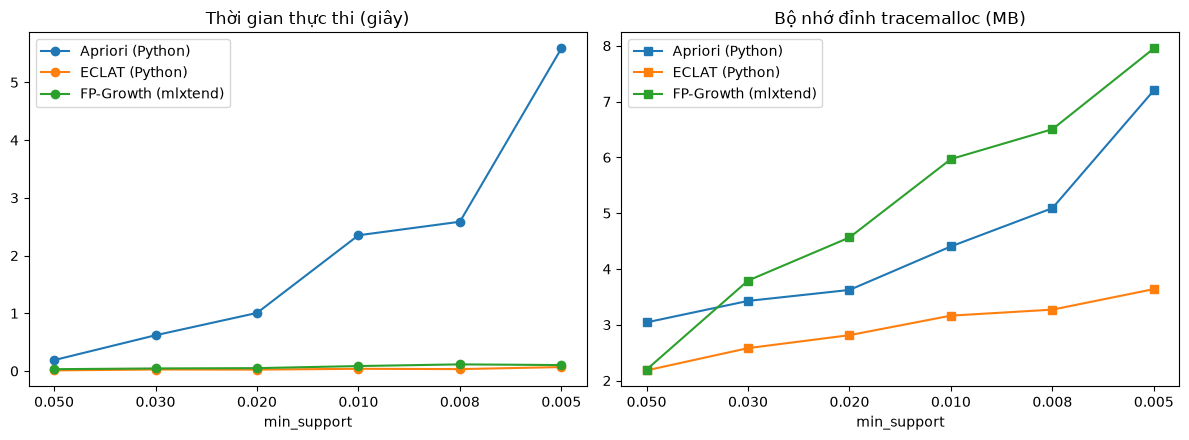

,min_support,algorithm,runtime_sec,peak_memory_mb,n_itemsets
0,0.050,FP-Growth (mlxtend),0.031397,2.196694,41
1,0.050,Apriori (Python),0.188321,3.042713,41
2,0.050,ECLAT (Python),0.010491,2.182171,41
3,0.030,FP-Growth (mlxtend),0.044474,3.791783,98
4,0.030,Apriori (Python),0.619159,3.427326,98
5,0.030,ECLAT (Python),0.025836,2.581242,98
6,0.020,FP-Growth (mlxtend),0.049668,4.564341,178
7,0.020,Apriori (Python),1.006001,3.624004,178
8,0.020,ECLAT (Python),0.024107,2.813412,178
9,0.010,FP-Growth (mlxtend),0.085761,5.969027,514


In [3]:
bench_df = benchmark_algorithms(bundle.df_train, support_thresholds=[0.05, 0.03, 0.02, 0.01, 0.008, 0.005], max_len=3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sup_order = ['0.050', '0.030', '0.020', '0.010', '0.008', '0.005']
bench_df['sup_str'] = bench_df['min_support'].map(lambda v: f'{v:.3f}')
for algo in ['Apriori (Python)', 'ECLAT (Python)', 'FP-Growth (mlxtend)']:
    sub = bench_df[bench_df['algorithm'] == algo].set_index('sup_str').loc[sup_order]
    axes[0].plot(sup_order, sub['runtime_sec'], marker='o', label=algo)
    axes[1].plot(sup_order, sub['peak_memory_mb'], marker='s', label=algo)
axes[0].set_title('Thời gian thực thi (giây)')
axes[0].set_xlabel('min_support')
axes[0].legend()
axes[1].set_title('Bộ nhớ đỉnh tracemalloc (MB)')
axes[1].set_xlabel('min_support')
axes[1].legend()
plt.tight_layout()
plt.show()
bench_df.drop(columns=['sup_str'])

## 3. Kiểm chứng trên tập Test 20% và Thử nghiệm gợi ý mua kèm

In [4]:
fp_res = mine_with_metrics(bundle.df_train, algorithm='FP-Growth (mlxtend)', min_support=0.008, min_confidence=0.25, min_lift=1.30, max_len=None)
eval_test = evaluate_rules_on_test(fp_res.rules, bundle.df_test)
print(f"Train Lift TB: {fp_res.rules['lift'].mean():.2f} -> Test Lift TB: {eval_test['test_lift'].mean():.2f}")
print(f"Train Conf TB: {fp_res.rules['confidence'].mean()*100:.2f}% -> Test Conf TB: {eval_test['test_confidence'].mean()*100:.2f}%")

rec, base = recommend_for_basket(['root vegetables', 'tropical fruit'], fp_res.rules, freq_train, top_k=5)
print('\nGợi ý cho giỏ [root vegetables, tropical fruit]:')
rec

Train Lift TB: 1.82 -> Test Lift TB: 1.70
Train Conf TB: 40.34% -> Test Conf TB: 34.71%

Gợi ý cho giỏ [root vegetables, tropical fruit]:


,recommended_item,triggered_by,confidence,lift,support,conviction
0,"other vegetables, whole milk","root vegetables, tropical fruit",0.352601,3.596298,0.009935,1.393197
1,other vegetables,"root vegetables, tropical fruit",0.595376,2.427362,0.016775,1.865244
2,yogurt,"root vegetables, tropical fruit",0.398844,2.273818,0.011238,1.371678
3,whole milk,"root vegetables, tropical fruit",0.572254,1.815835,0.016124,1.601076
